In [34]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
import pandas as pd
dataset='/content/drive/MyDrive/Dhaka.csv'

In [36]:
df = pd.read_csv(dataset)
df

,Unnamed: 0,Station,Year,Month,Day,Rainfall,Sunshine,Humidity,Temperature
0,153400,Dhaka,1961,1,1,0.5,0.4,80.0,21.5
1,153401,Dhaka,1961,1,2,1.0,5.9,76.0,22.2
2,153402,Dhaka,1961,1,3,0.0,4.2,75.0,23.1
3,153403,Dhaka,1961,1,4,0.0,6.8,74.0,19.8
4,153404,Dhaka,1961,1,5,0.0,10.0,68.0,16.6
...,...,...,...,...,...,...,...,...,...
23005,176405,Dhaka,2023,12,27,0.0,0.0,76.0,21.8
23006,176406,Dhaka,2023,12,28,0.0,3.4,74.0,21.8
23007,176407,Dhaka,2023,12,29,0.0,4.7,76.0,21.8
23008,176408,Dhaka,2023,12,30,0.0,0.0,68.0,22.8


In [37]:
df=df.drop(['Station','Unnamed: 0'],axis=1)
df.head()

,Year,Month,Day,Rainfall,Sunshine,Humidity,Temperature
0,1961,1,1,0.5,0.4,80.0,21.5
1,1961,1,2,1.0,5.9,76.0,22.2
2,1961,1,3,0.0,4.2,75.0,23.1
3,1961,1,4,0.0,6.8,74.0,19.8
4,1961,1,5,0.0,10.0,68.0,16.6


In [38]:
df.isnull().sum()

,0
Year,0
Month,0
Day,0
Rainfall,0
Sunshine,0
Humidity,0
Temperature,0


In [39]:
df.describe()

,Year,Month,Day,Rainfall,Sunshine,Humidity,Temperature
count,23010.000000,23010.000000,23010.000000,23010.000000,23010.000000,23010.000000,23010.000000
mean,1992.000000,6.523077,15.729205,5.507048,6.518466,74.615072,25.835671
std,18.184064,3.448738,8.800101,15.588238,3.247169,10.973908,4.118754
min,1961.000000,1.000000,1.000000,0.000000,0.000000,29.000000,10.400000
25%,1976.000000,4.000000,8.000000,0.000000,4.300000,68.000000,22.900000
50%,1992.000000,7.000000,16.000000,0.000000,7.400000,76.000000,27.200000
75%,2008.000000,10.000000,23.000000,2.000000,9.100000,83.000000,29.000000
max,2023.000000,12.000000,31.000000,341.000000,13.800000,100.000000,37.800000


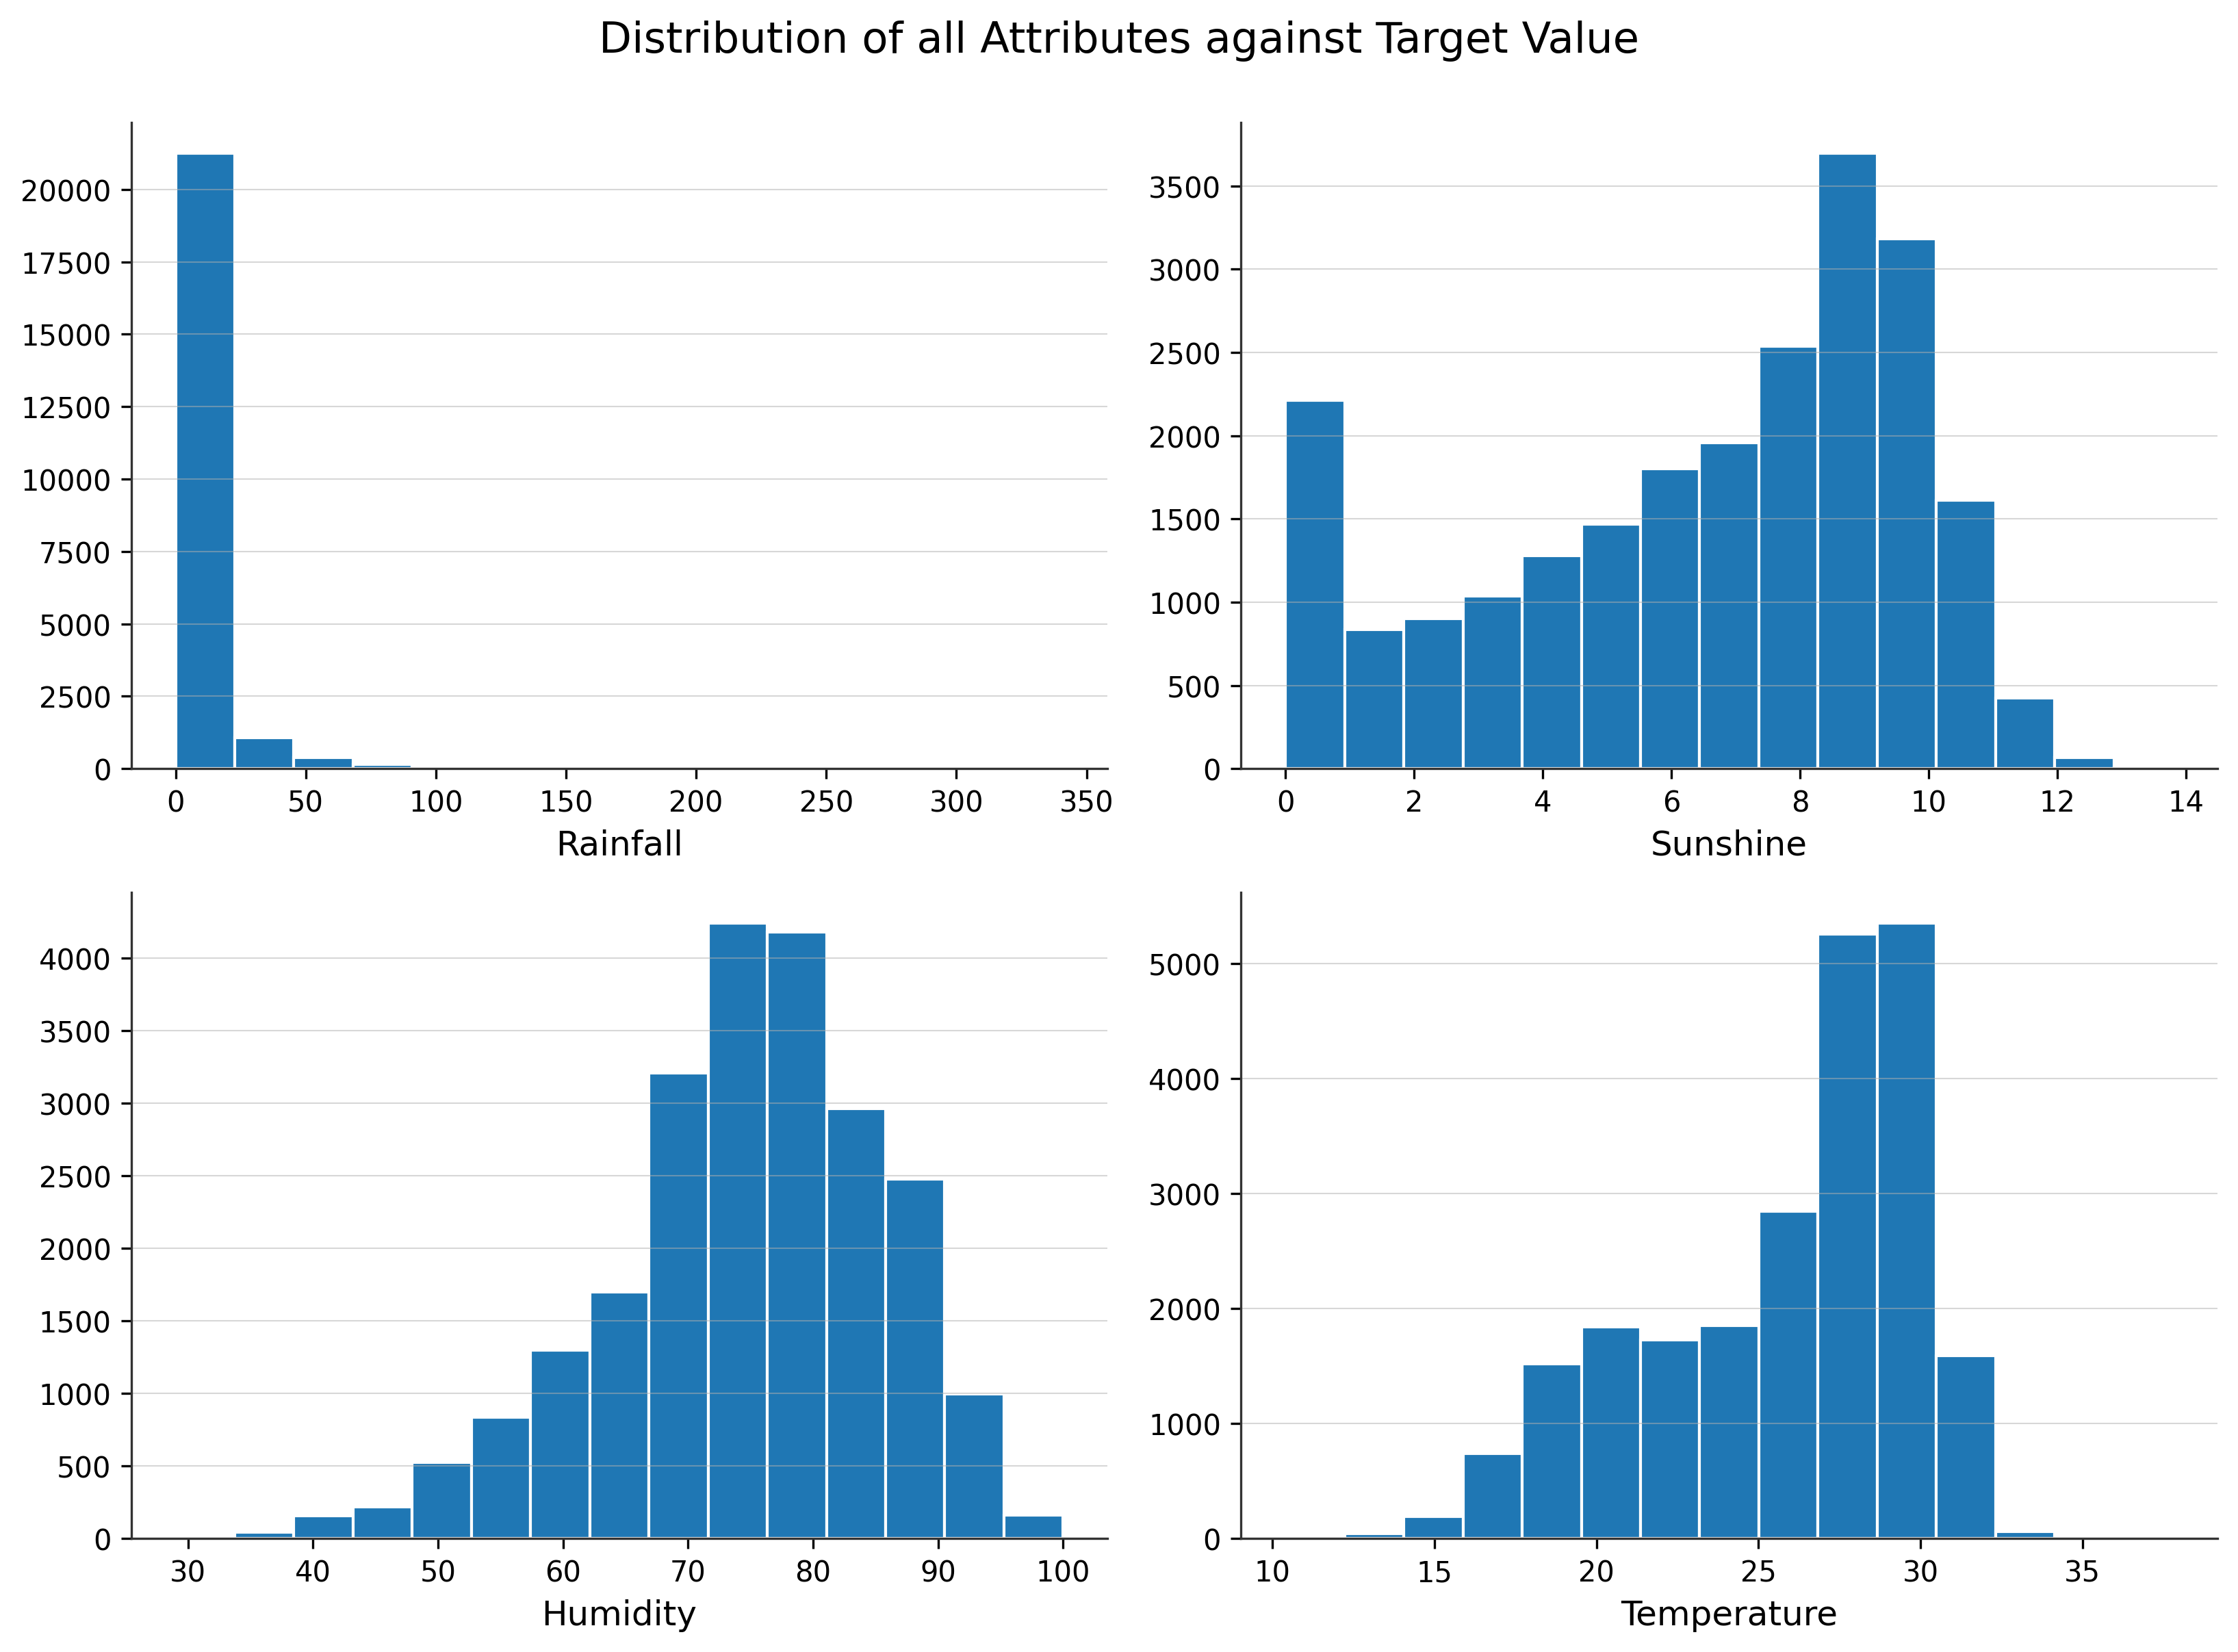

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

 # adjust path as needed

params = ['Rainfall', 'Sunshine', 'Humidity', 'Temperature']

mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.size'] = 10

fig, axes = plt.subplots(2, 2, figsize=(11, 8), dpi=300)
axes = axes.flatten()

for ax, param in zip(axes, params):
    ax.hist(df[param].dropna(), bins=15, color='#1f77b4', edgecolor='white')
    ax.set_xlabel(param)
    # ax.set_ylabel('RainToday')  # target label, change if using a different target
    ax.grid(axis='y', linestyle='-', linewidth=0.5, alpha=0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.suptitle('Distribution of all Attributes against Target Value', fontsize=15, y=1.0)
plt.tight_layout()
plt.savefig('chittagong_dist_vs_target.png', dpi=300, bbox_inches='tight')
plt.show()

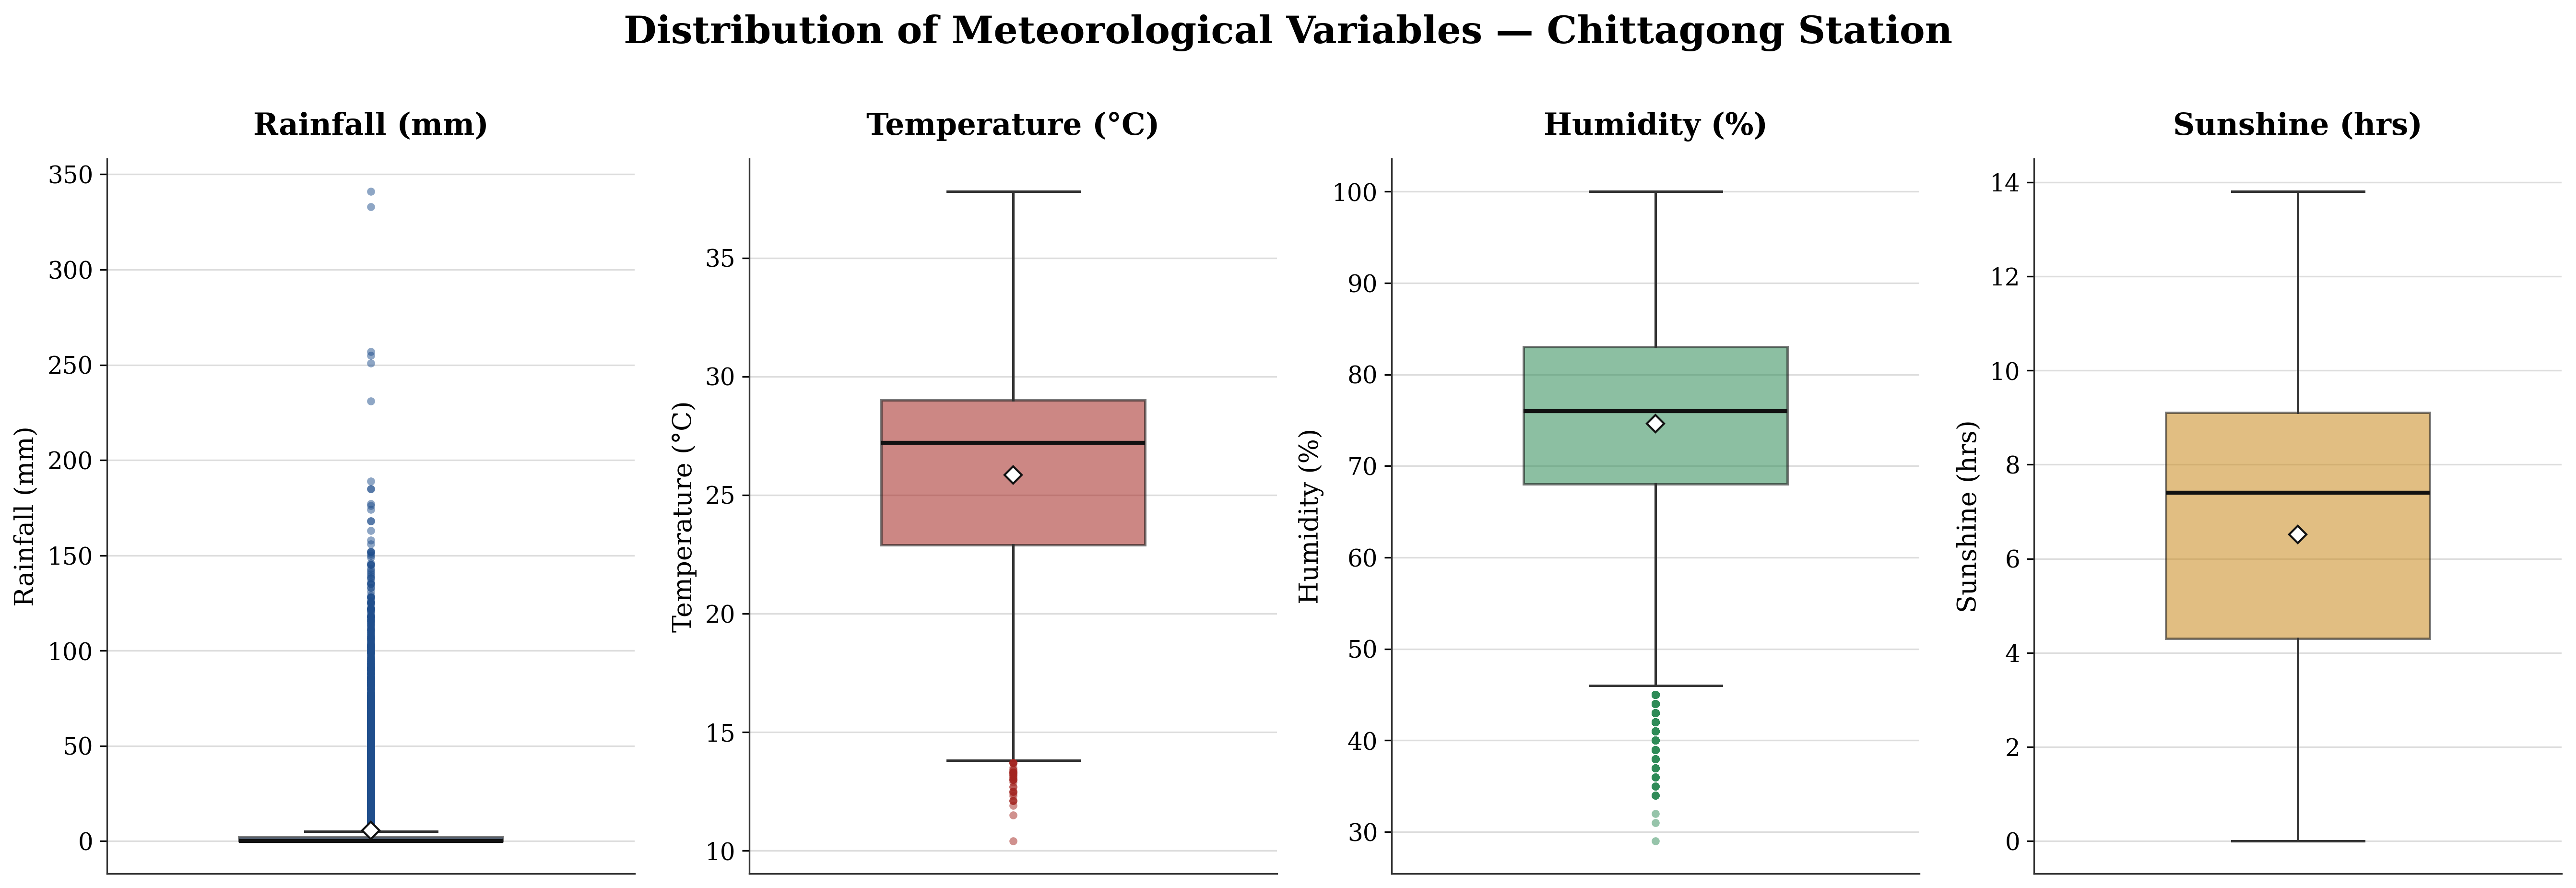

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# ==========================================================
# Publication Style
# ==========================================================
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']

mpl.rcParams['axes.titlesize'] = 17
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 12
mpl.rcParams['ytick.labelsize'] = 12

mpl.rcParams['axes.edgecolor'] = '#333333'
mpl.rcParams['axes.linewidth'] = 0.8
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['savefig.dpi'] = 600



# ==========================================================
# Variables to Plot
# ==========================================================
variables = ['Rainfall', 'Temperature', 'Humidity', 'Sunshine']

pretty = {
    'Rainfall': 'Rainfall (mm)',
    'Temperature': 'Temperature (°C)',
    'Humidity': 'Humidity (%)',
    'Sunshine': 'Sunshine (hrs)'
}

# Box + accent colors (one per variable)
colors = ['#1f4e8c', '#a3241f', '#2e8b57', '#c98a1c']


# ==========================================================
# Figure
# ==========================================================
fig, axes = plt.subplots(
    1, len(variables),
    figsize=(18, 6)
)

for ax, var, color in zip(axes, variables, colors):

    box = ax.boxplot(
        df[var].dropna(),
        patch_artist=True,
        widths=0.5,
        showmeans=True,
        meanprops={
            'marker': 'D',
            'markerfacecolor': 'white',
            'markeredgecolor': '#111111',
            'markersize': 6
        },
        medianprops={
            'color': '#111111',
            'linewidth': 2
        },
        whiskerprops={
            'color': '#333333',
            'linewidth': 1.2
        },
        capprops={
            'color': '#333333',
            'linewidth': 1.2
        },
        flierprops={
            'marker': 'o',
            'markerfacecolor': color,
            'markeredgecolor': 'none',
            'markersize': 4,
            'alpha': 0.5
        }
    )

    # Fill box
    for patch in box['boxes']:
        patch.set_facecolor(color)
        patch.set_alpha(0.55)
        patch.set_edgecolor('#111111')
        patch.set_linewidth(1.2)

    # ------------------------------------------------------
    # Axis Styling
    # ------------------------------------------------------
    ax.set_title(pretty[var], fontsize=15, fontweight='bold', pad=12)
    ax.set_xticks([])
    ax.set_ylabel(pretty[var], fontsize=13)

    ax.grid(axis='y', color='#dddddd', linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)


# ==========================================================
# Main Title
# ==========================================================
fig.suptitle(
    "Distribution of Meteorological Variables — Chittagong Station",
    fontsize=19,
    fontweight='bold',
    y=1.02
)

fig.tight_layout()


# ==========================================================
# Save Figure
# ==========================================================
plt.savefig(
    "Meteorological_Boxplots.png",
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

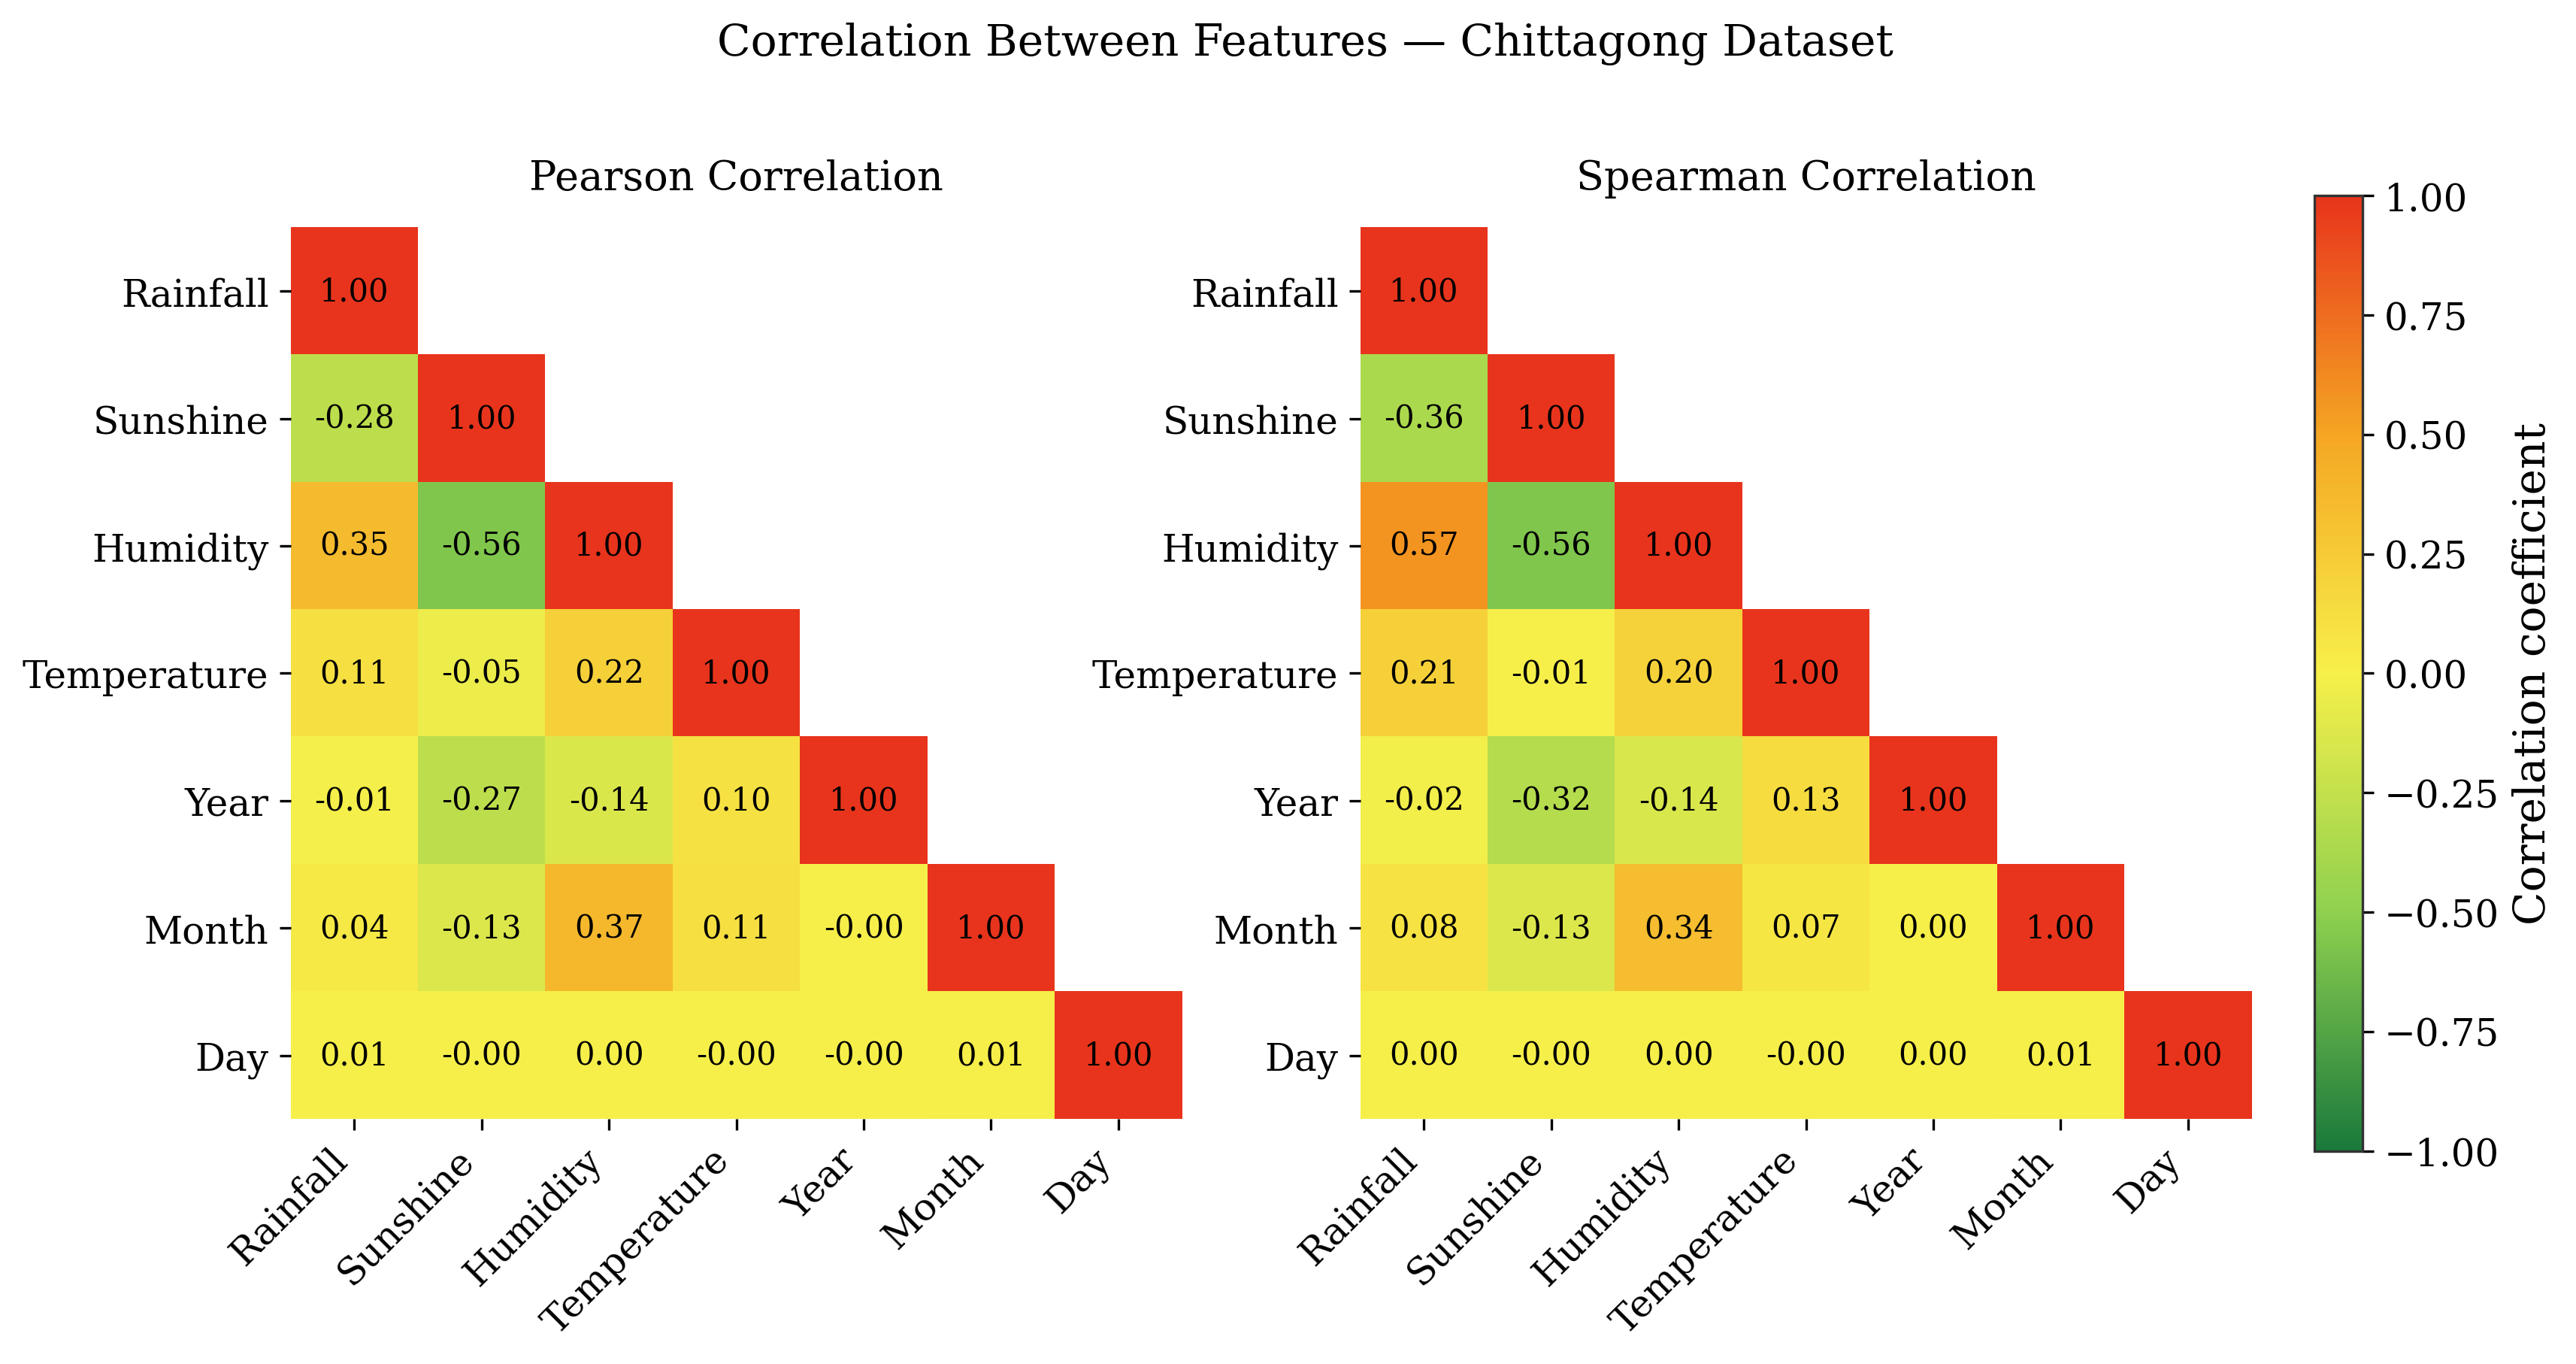

In [42]:
"""
Pearson & Spearman Correlation Heatmaps -- Chittagong dataset
(Rainfall, Sunshine, Humidity, Temperature)

Style matches the reference figure: lower-triangle heatmap,
red-yellow-green diverging colormap, annotated correlation values.

Output: correlation_heatmaps.png
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ------------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------------
df = pd.read_csv(dataset)

features = ["Rainfall", "Sunshine", "Humidity", "Temperature","Year","Month","Day"]
data = df[features]

pearson_corr  = data.corr(method="pearson")
spearman_corr = data.corr(method="spearman")

# ------------------------------------------------------------------
# 2. Red -> Yellow -> Green diverging colormap (like reference figure)
# ------------------------------------------------------------------
cmap = LinearSegmentedColormap.from_list(
    "RdYlGn_r_custom",
    ["#1a7a3c", "#8fd14f", "#f7f04a", "#f5a623", "#e8341c"],
    N=256,
)

def plot_triangular_heatmap(ax, corr, title):
    n = len(corr)
    mask = np.triu(np.ones((n, n), dtype=bool), k=1)  # hide upper triangle
    corr_masked = np.ma.array(corr.values, mask=mask)

    im = ax.imshow(corr_masked, cmap=cmap, vmin=-1, vmax=1)

    # annotate cells
    for i in range(n):
        for j in range(n):
            if j <= i:
                val = corr.values[i, j]
                ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                         fontsize=10, color="black")

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(corr.columns, rotation=45, ha="right")
    ax.set_yticklabels(corr.columns)
    ax.set_title(title, fontsize=13, pad=12)

    # remove upper-right ticks/spines look cleaner
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.grid(False)

    return im

# ------------------------------------------------------------------
# 3. Plot side by side
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

im1 = plot_triangular_heatmap(axes[0], pearson_corr,  "Pearson Correlation")
im2 = plot_triangular_heatmap(axes[1], spearman_corr, "Spearman Correlation")

# single shared colorbar
cbar = fig.colorbar(im2, ax=axes, orientation="vertical",
                     fraction=0.035, pad=0.03)
cbar.set_label("Correlation coefficient")

fig.suptitle("Correlation Between Features — Chittagong Dataset",
             fontsize=14, y=1.02)

fig.savefig("correlation_heatmaps.png", dpi=300, bbox_inches="tight",
            facecolor="white")

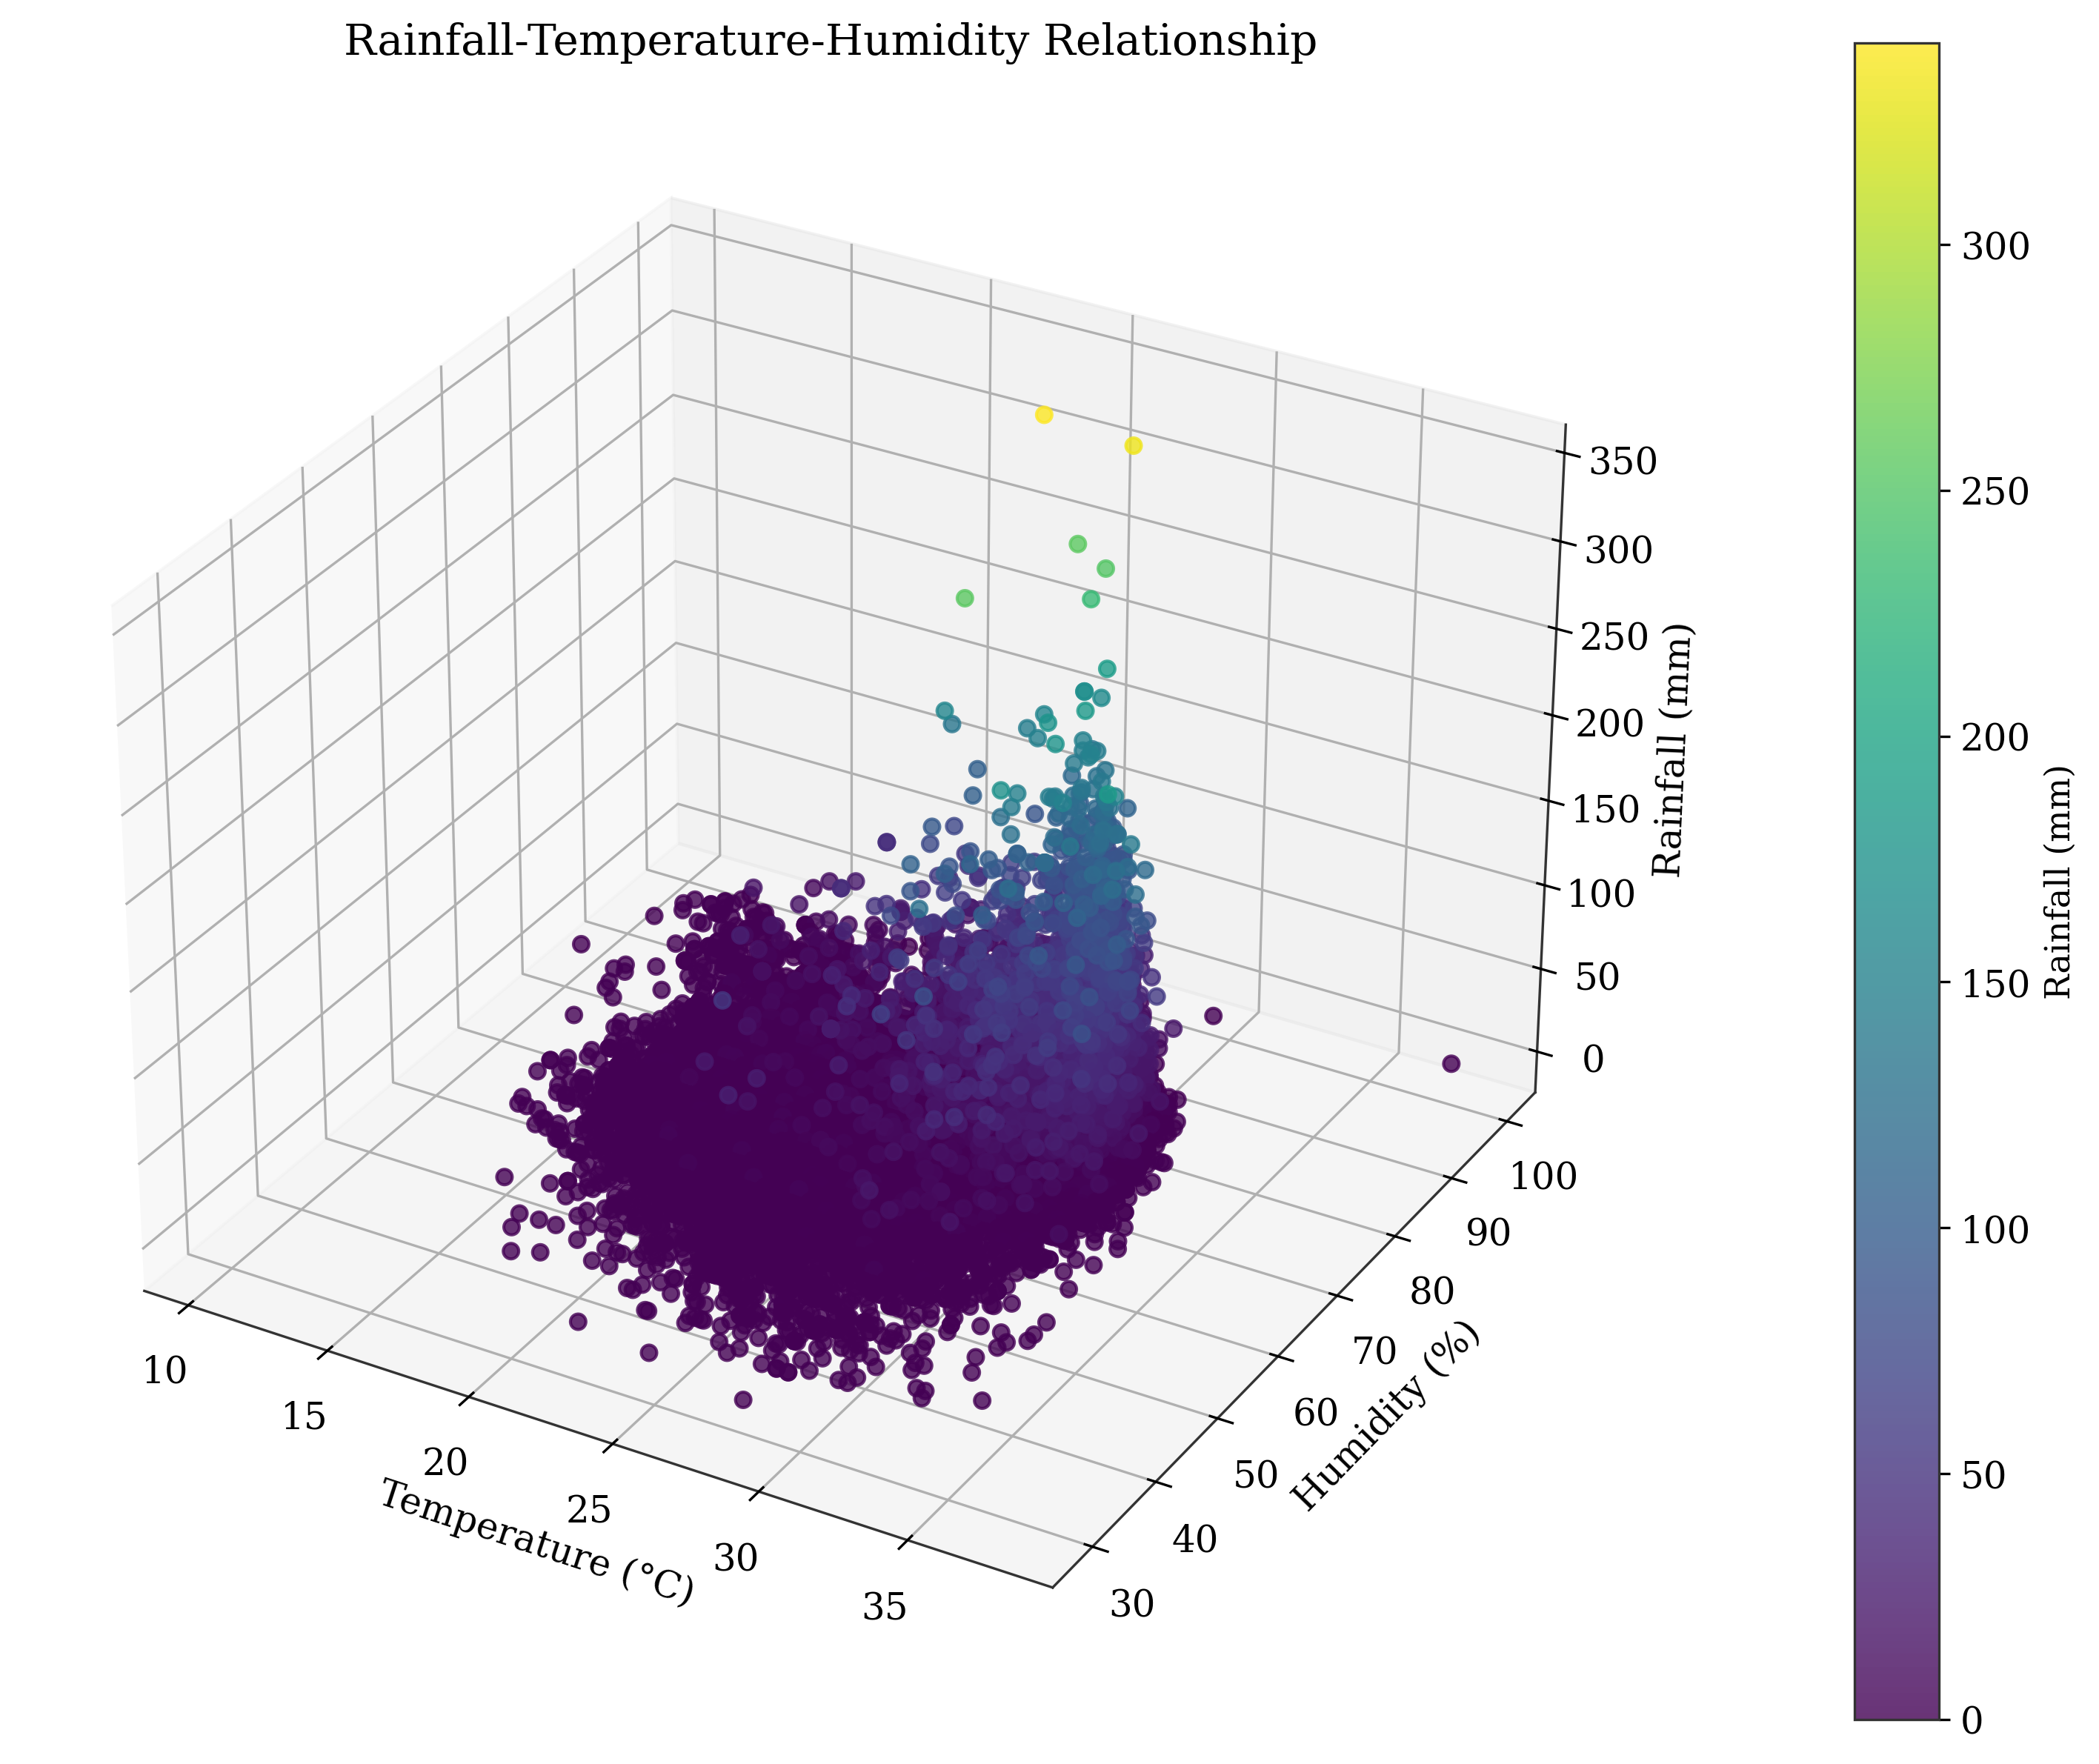

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Read dataset


# Drop missing values
df = df[['Temperature', 'Humidity', 'Rainfall']].dropna()

# Create figure
fig = plt.figure(figsize=(10,8), dpi=300)
ax = fig.add_subplot(111, projection='3d')

# 3D Scatter
sc = ax.scatter(
    df['Temperature'],
    df['Humidity'],
    df['Rainfall'],
    c=df['Rainfall'],
    cmap='viridis',
    s=25,
    alpha=0.8
)

# Labels
ax.set_xlabel('Temperature (°C)', fontsize=12)
ax.set_ylabel('Humidity (%)', fontsize=12)
ax.set_zlabel('Rainfall (mm)', fontsize=12)

# Colorbar
cbar = plt.colorbar(sc, pad=0.1)
cbar.set_label('Rainfall (mm)', fontsize=11)

# Title
plt.title('Rainfall-Temperature-Humidity Relationship', fontsize=14)

plt.tight_layout()

# Save publication-quality figure
plt.savefig("3D_Rainfall_Surface.png", dpi=600, bbox_inches='tight')

plt.show()

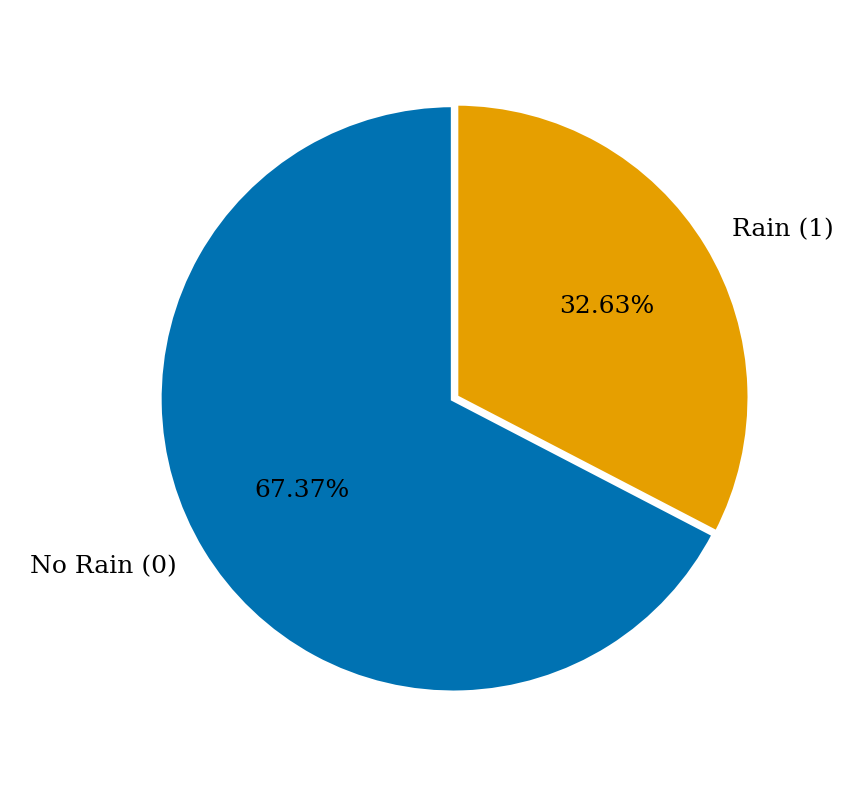

In [44]:
import matplotlib.pyplot as plt
df['RainToday'] = df['Rainfall'].apply(lambda x: 'Yes' if x > 0 else 'No')

# Calculate the counts of 'Rain' (0) and 'No Rain' (1) from the 'Rainfall today' column
rain_counts = df['RainToday'].value_counts().sort_index()

plt.figure(figsize=(3,3))

plt.pie(
    rain_counts,
    labels=[ 'No Rain (0)','Rain (1)'],
    colors=['#0072B2', '#E69F00'],
    autopct='%1.2f%%',
    startangle=90,
    explode=(0.01, 0),
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1.2
    },
    textprops={
        'fontsize': 6
    }
)


plt.tight_layout()
plt.show()

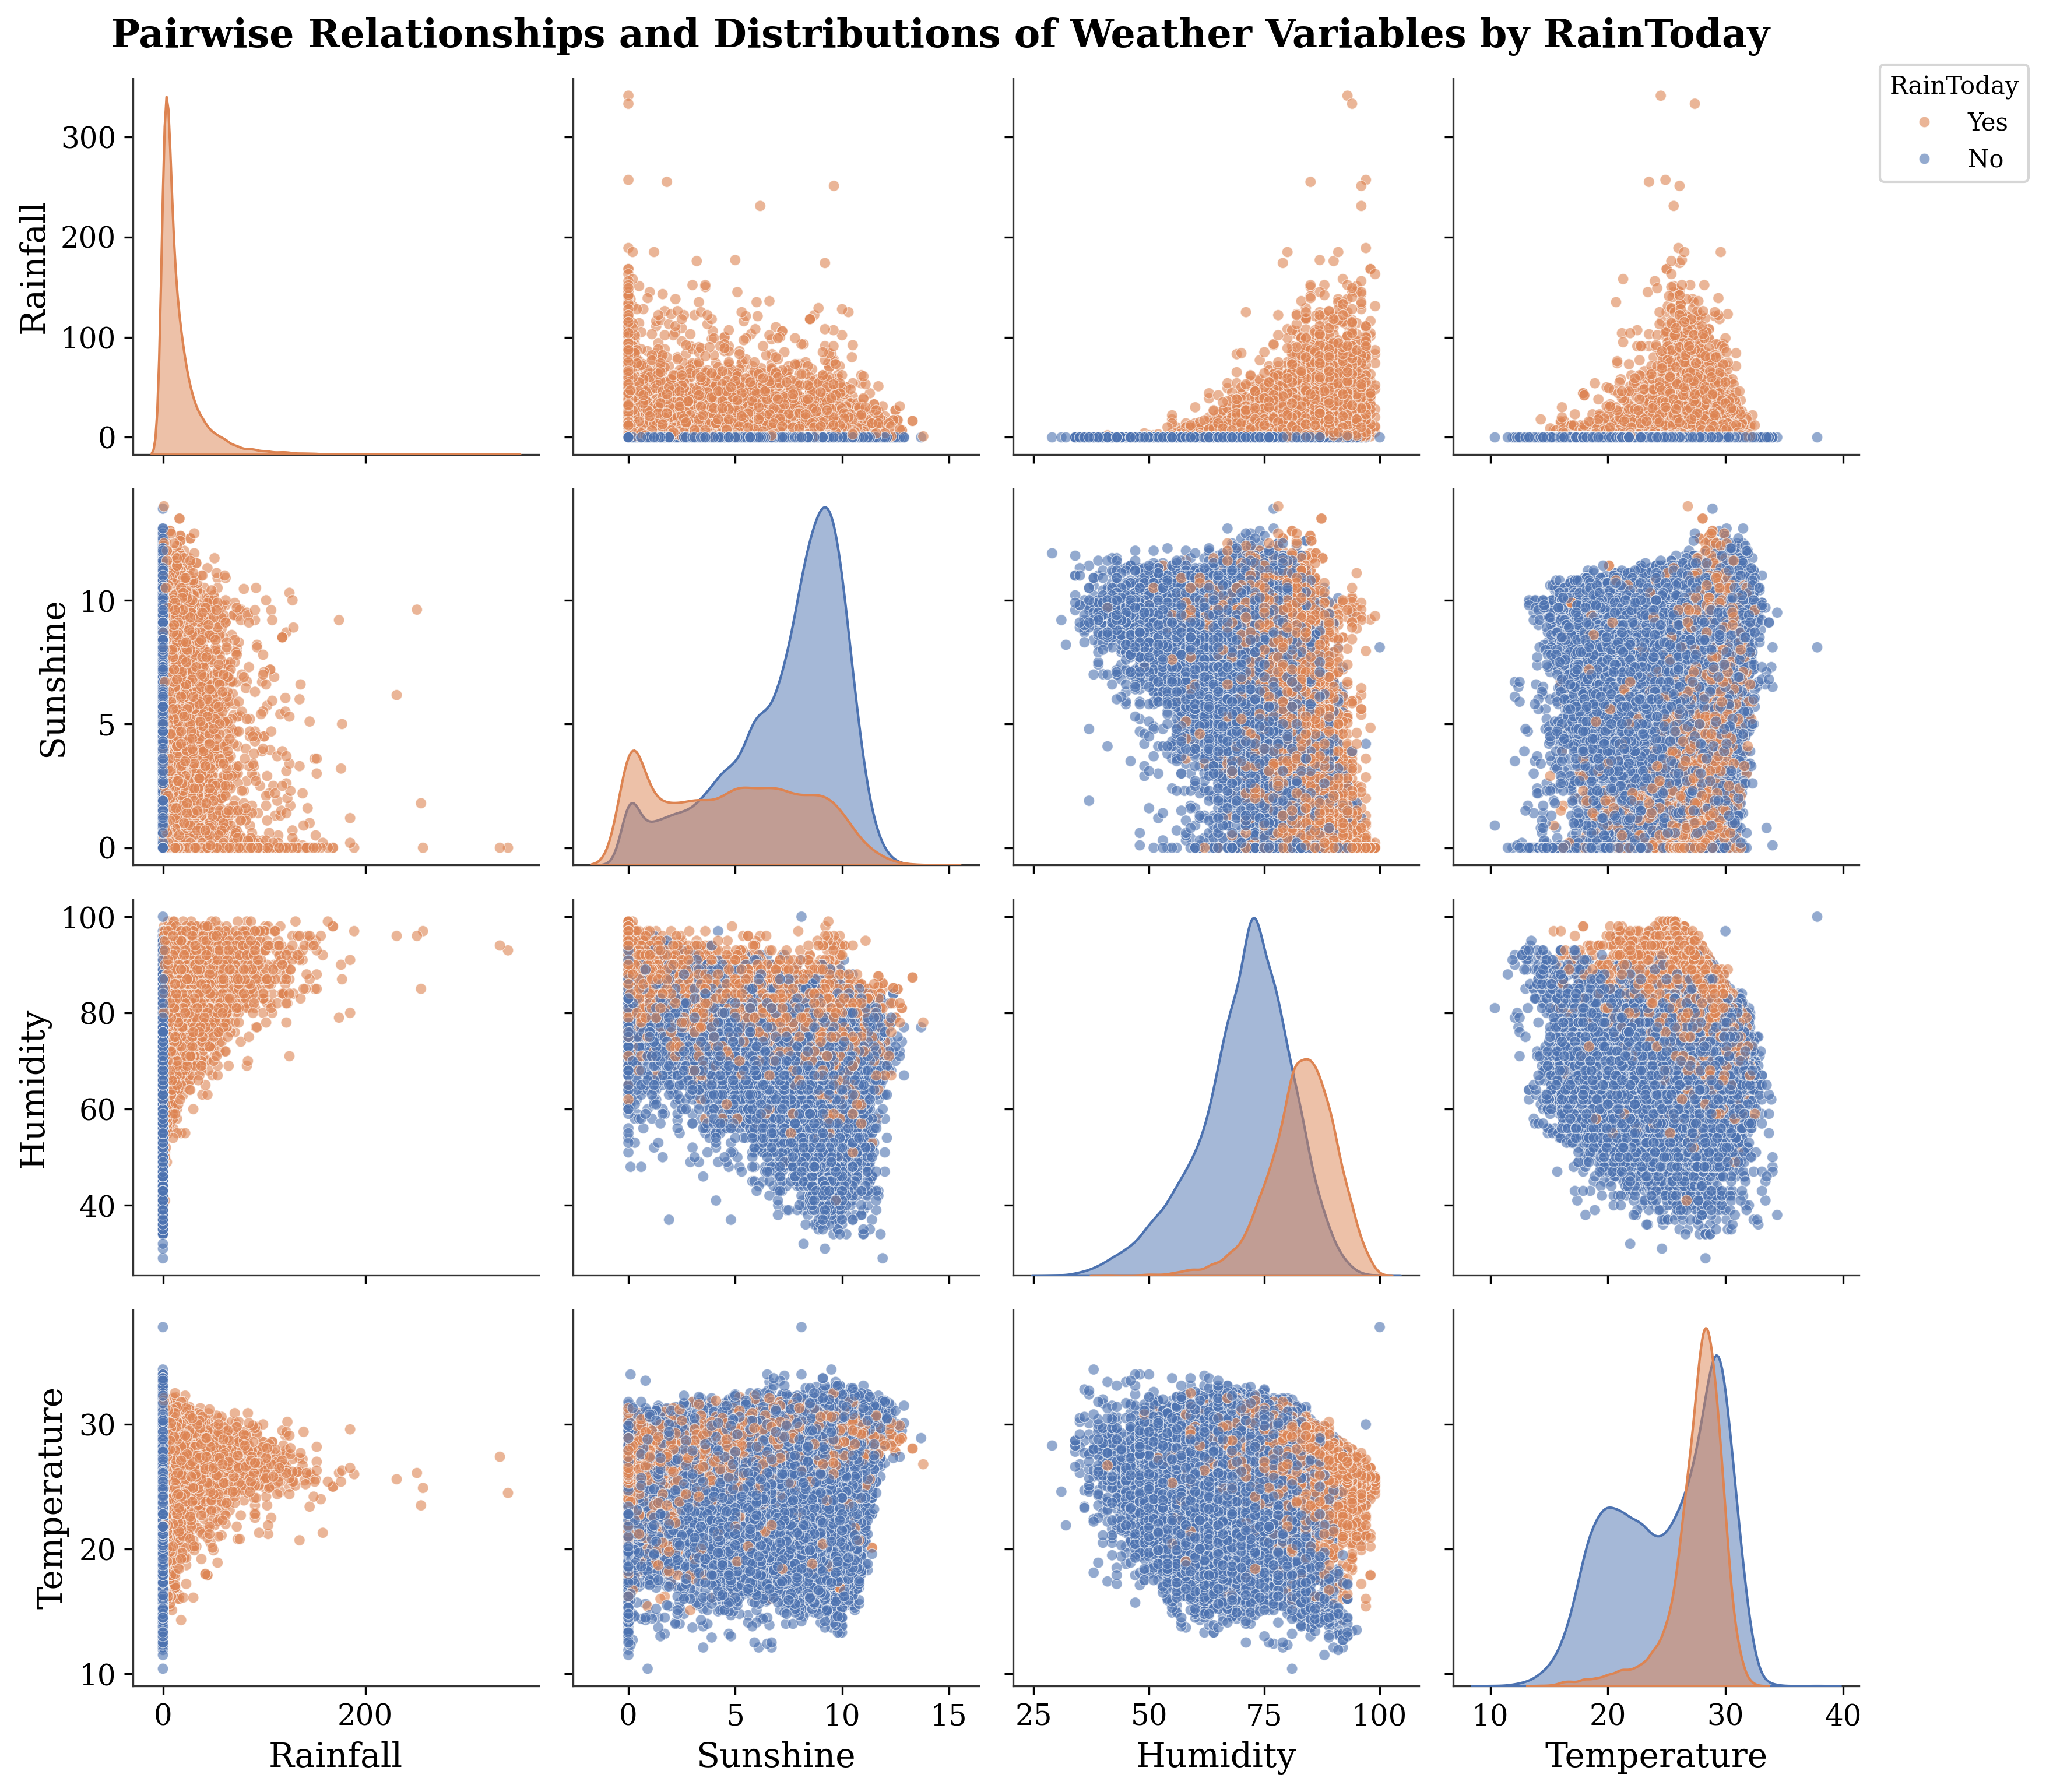

In [45]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

df = pd.read_csv(dataset)  # adjust path as needed

# Derived categorical target for hue (change condition/threshold as needed)
df['RainToday'] = df['Rainfall'].apply(lambda x: 'Yes' if x > 0 else 'No')

params = ['Rainfall', 'Sunshine', 'Humidity', 'Temperature']

mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.size'] = 10

g = sns.pairplot(
    df[params + ['RainToday']],
    hue='RainToday',
    palette={'No': '#4C72B0', 'Yes': '#DD8452'},
    diag_kind='kde',
    plot_kws=dict(alpha=0.6, s=20, edgecolor='white', linewidth=0.3),
    diag_kws=dict(fill=True, alpha=0.5),
    corner=False
)

g.fig.set_dpi(300)
g._legend.set_title('RainToday')
plt.tight_layout()
g.fig.suptitle(
    'Pairwise Relationships and Distributions of Weather Variables by RainToday',
    fontsize=16,
    fontweight='bold',
    y=1.02
)
# Move legend outside the plot area so it doesn't overlap the diagonal panels
sns.move_legend(g, "upper right", bbox_to_anchor=(1.08, 1.0), title='RainToday', frameon=True)
plt.savefig('chittagong_pairplot.png', dpi=300, bbox_inches='tight')
plt.show()

In [46]:
df = pd.read_csv(dataset)
df

,Unnamed: 0,Station,Year,Month,Day,Rainfall,Sunshine,Humidity,Temperature
0,153400,Dhaka,1961,1,1,0.5,0.4,80.0,21.5
1,153401,Dhaka,1961,1,2,1.0,5.9,76.0,22.2
2,153402,Dhaka,1961,1,3,0.0,4.2,75.0,23.1
3,153403,Dhaka,1961,1,4,0.0,6.8,74.0,19.8
4,153404,Dhaka,1961,1,5,0.0,10.0,68.0,16.6
...,...,...,...,...,...,...,...,...,...
23005,176405,Dhaka,2023,12,27,0.0,0.0,76.0,21.8
23006,176406,Dhaka,2023,12,28,0.0,3.4,74.0,21.8
23007,176407,Dhaka,2023,12,29,0.0,4.7,76.0,21.8
23008,176408,Dhaka,2023,12,30,0.0,0.0,68.0,22.8


In [47]:
df=df.drop(['Station','Unnamed: 0'],axis=1)
df.head()

,Year,Month,Day,Rainfall,Sunshine,Humidity,Temperature
0,1961,1,1,0.5,0.4,80.0,21.5
1,1961,1,2,1.0,5.9,76.0,22.2
2,1961,1,3,0.0,4.2,75.0,23.1
3,1961,1,4,0.0,6.8,74.0,19.8
4,1961,1,5,0.0,10.0,68.0,16.6


In [48]:
df['Rainfall today']=df['Rainfall'].apply(lambda x: 'N0' if x==0 else 'Yes')

In [49]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Rainfall today'] = le.fit_transform(df['Rainfall today'])

In [50]:
df.drop('Rainfall',axis=1,inplace=True)

In [51]:
df.head()

,Year,Month,Day,Sunshine,Humidity,Temperature,Rainfall today
0,1961,1,1,0.4,80.0,21.5,1
1,1961,1,2,5.9,76.0,22.2,1
2,1961,1,3,4.2,75.0,23.1,0
3,1961,1,4,6.8,74.0,19.8,0
4,1961,1,5,10.0,68.0,16.6,0


In [52]:
from sklearn.preprocessing import QuantileTransformer

features = [
    'Temperature',

    'Humidity',
    'Sunshine'
]

qt = QuantileTransformer(
    n_quantiles=100,
    output_distribution='normal',
    random_state=42
)

# Create transformed columns
for col in features:
    df[col] = qt.fit_transform(
        df[[col]]
    )

# Display
print(
    df[

        [col for col in features]
    ].head()
)

   Temperature  Humidity  Sunshine
0    -0.852495  0.403108 -1.508944
1    -0.753452  0.037988 -0.348756
2    -0.624976 -0.050661 -0.698526
3    -1.168949 -0.139710 -0.139710
4    -2.076164 -0.682458  1.247754


In [53]:
df

,Year,Month,Day,Sunshine,Humidity,Temperature,Rainfall today
0,1961,1,1,-1.508944,0.403108,-0.852495,1
1,1961,1,2,-0.348756,0.037988,-0.753452,1
2,1961,1,3,-0.698526,-0.050661,-0.624976,0
3,1961,1,4,-0.139710,-0.139710,-1.168949,0
4,1961,1,5,1.247754,-0.682458,-2.076164,0
...,...,...,...,...,...,...,...
23005,2023,12,27,-5.199338,0.037988,-0.799083,0
23006,2023,12,28,-0.834427,-0.139710,-0.799083,0
23007,2023,12,29,-0.604585,0.037988,-0.799083,0
23008,2023,12,30,-5.199338,-0.682458,-0.666564,0


In [54]:
x=df.drop('Rainfall today',axis=1)
y=df['Rainfall today']

In [55]:
df = df.sort_index()

In [56]:
train_size = int(len(df) * 0.8)
val_size = int(len(df) * 0.1)

train = df.iloc[:train_size]
val = df.iloc[train_size:train_size + val_size]
test = df.iloc[train_size + val_size:]

In [57]:
TARGET = 'Rainfall today'

x_train = train.drop(TARGET, axis=1)
y_train = train[TARGET]

x_val = val.drop(TARGET, axis=1)
y_val = val[TARGET]

x_test = test.drop(TARGET, axis=1)
y_test = test[TARGET]

In [58]:
print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)

Train: (18408, 6) (18408,)
Validation: (2301, 6) (2301,)
Test: (2301, 6) (2301,)


In [59]:
print(x_train.index.min(), x_train.index.max())
print(x_val.index.min(), x_val.index.max())
print(x_test.index.min(), x_test.index.max())

0 18407
18408 20708
20709 23009


In [60]:
from sklearn.svm import LinearSVC, SVC
from sklearn.linear_model import LogisticRegression, Perceptron, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),

    'Support Vector Machines': SVC(
        probability=True,
        random_state=42
    ),

    'Linear SVC': LinearSVC(

    ),

    'k-Nearest Neighbors': KNeighborsClassifier(),

    'Naive Bayes': GaussianNB(),

    'Perceptron': Perceptron(
        random_state=42
    ),

    'Stochastic Gradient Descent': SGDClassifier(
        random_state=42
    ),

    'Decision Tree Classifier': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        random_state=42
    ),

    'XGBClassifier': XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    ),

    'GradientBoostingClassifier': GradientBoostingClassifier(
        random_state=42
    ),

    'AdaBoostClassifier': AdaBoostClassifier(
        random_state=42
    )
}
LinearSVC(

)

LinearSVC()

In [61]:
import time
from sklearn.feature_selection import RFE
from sklearn.metrics import accuracy_score, mean_squared_error, precision_score, recall_score, f1_score
import numpy as np # Import numpy to use isinf and isnan

results_list = [] # Initialize results_list



# Training and evaluating the models
for model_name, model in models.items():
    start_time = time.time()



    # # Fit the model
    model.fit(x_train, y_train)

    # -------- Training set --------
    y_train_pred = model.predict(x_train)
    train_accuracy = accuracy_score(y_train, y_train_pred)
    train_mse = mean_squared_error(y_train, y_train_pred)
    train_precision = precision_score(
        y_train, y_train_pred, average='weighted'
    )
    train_recall = recall_score(
        y_train, y_train_pred, average='weighted'
    )
    train_f1 = f1_score(
        y_train, y_train_pred, average='weighted'
    )

    # Validation set
    y_val_pred = model.predict(x_val) # Corrected X_val to x_val and indented
    val_accuracy = accuracy_score(y_val, y_val_pred)
    val_mse = mean_squared_error(y_val, y_val_pred)
    val_precision = precision_score(y_val, y_val_pred, average='weighted')
    val_recall = recall_score(y_val, y_val_pred, average='weighted')
    val_f1 = f1_score(y_val, y_val_pred, average='weighted')

    # -------- Testing set --------
    y_test_pred = model.predict(x_test)
    test_accuracy = accuracy_score(y_test, y_test_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)
    test_precision = precision_score(
        y_test, y_test_pred, average='weighted'
    )
    test_recall = recall_score(
        y_test, y_test_pred, average='weighted'
    )
    test_f1 = f1_score(
        y_test, y_test_pred, average='weighted'
    )

    cpu_time = time.time() - start_time

    # -------- Store results --------
    results_list.append({
        'Model': model_name,
        'Training Accuracy': train_accuracy,
        'Validation Accuracy': val_accuracy, # Added validation metric
        'Testing Accuracy': test_accuracy,
        'Training MSE': train_mse,
        'Validation MSE': val_mse, # Added validation metric
        'Testing MSE': test_mse,
        'Training Precision': train_precision,
        'Validation Precision': val_precision, # Added validation metric
        'Testing Precision': test_precision,
        'Training Recall': train_recall,
        'Testing Recall': test_recall,
        'Validation Recall': val_recall, # Added validation metric
        'Testing F1': test_f1,
        'CPU Time (s)': cpu_time,
        'Training F1': train_f1,
        'Validation F1': val_f1 # Added validation metric
    })


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

In [62]:
model_1=pd.DataFrame(results_list)
model_1

,Model,Training Accuracy,Validation Accuracy,Testing Accuracy,Training MSE,Validation MSE,Testing MSE,Training Precision,Validation Precision,Testing Precision,Training Recall,Testing Recall,Validation Recall,Testing F1,CPU Time (s),Training F1,Validation F1
0,Logistic Regression,0.799815,0.790960,0.774446,0.200185,0.209040,0.225554,0.796421,0.784768,0.777754,0.799815,0.774446,0.790960,0.775914,0.974565,0.797457,0.783020
1,Support Vector Machines,0.670904,0.677532,0.692308,0.329096,0.322468,0.307692,0.450112,0.459049,0.479290,0.670904,0.692308,0.677532,0.566434,83.963398,0.538765,0.547291
2,Linear SVC,0.797642,0.767058,0.772708,0.202358,0.232942,0.227292,0.793996,0.765117,0.762666,0.797642,0.772708,0.767058,0.761416,0.075557,0.795051,0.743894
3,k-Nearest Neighbors,0.857888,0.737071,0.737940,0.142112,0.262929,0.262060,0.857690,0.735533,0.744459,0.857888,0.737940,0.737071,0.740709,0.253699,0.857786,0.736260
4,Naive Bayes,0.801608,0.794437,0.772708,0.198392,0.205563,0.227292,0.802475,0.789346,0.766185,0.801608,0.772708,0.794437,0.768174,0.056587,0.802017,0.790253
5,Perceptron,0.670904,0.677532,0.692308,0.329096,0.322468,0.307692,0.450112,0.459049,0.479290,0.670904,0.692308,0.677532,0.566434,0.067227,0.538765,0.547291
6,Stochastic Gradient Descent,0.738755,0.729683,0.732290,0.261245,0.270317,0.267710,0.749657,0.730364,0.716649,0.738755,0.732290,0.729683,0.692378,0.223716,0.695280,0.682427
7,Decision Tree Classifier,1.000000,0.739244,0.739244,0.000000,0.260756,0.260756,1.000000,0.738696,0.740914,1.000000,0.739244,0.739244,0.740042,0.131522,1.000000,0.738965
8,Random Forest,1.000000,0.802260,0.796610,0.000000,0.197740,0.203390,1.000000,0.799556,0.791845,1.000000,0.796610,0.802260,0.793311,2.658230,1.000000,0.800575
9,XGBClassifier,0.895154,0.797045,0.804867,0.104846,0.202955,0.195133,0.897013,0.799975,0.805414,0.895154,0.804867,0.797045,0.805133,2.515009,0.895804,0.798295
